In [23]:
from pathlib import Path
import hashlib
import json
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

diretorio_atual = Path.cwd().resolve()

ROOT = next(
    (
        pasta
        for pasta in (diretorio_atual, *diretorio_atual.parents)
        if (pasta / "code" / "sensores.json").is_file()
    ),
    None,
)

if ROOT is None:
    raise RuntimeError("Execute o notebook dentro do projeto.")

BASE_DIR = ROOT / "code" / "tcc"
PROCESSED_DIR = BASE_DIR / "data" / "processed"
RESULTS_DIR = BASE_DIR / "results" / "experimentos"

TABLE_DIR = RESULTS_DIR / "tabelas"
FIG_DIR = RESULTS_DIR / "figuras"

for pasta in (RESULTS_DIR, TABLE_DIR, FIG_DIR):
    pasta.mkdir(parents=True, exist_ok=True)

ARQUIVO_DADOS = (
    PROCESSED_DIR / "temperaturas_1006_5min_completas.csv"
)

SENSOR_IDS = [
    1, 48, 887, 891, 86782,
    86789, 86790, 86791, 86793,
]

SEMENTE = 42
FRACAO_TREINO = 0.7

pd.set_option("display.max_columns", 20)

print("Dados:", ARQUIVO_DADOS)
print("Resultados:", RESULTS_DIR)

Dados: /home/gustavomoura/Documents/temperatureMonitoring/code/tcc/data/processed/temperaturas_1006_5min_completas.csv
Resultados: /home/gustavomoura/Documents/temperatureMonitoring/code/tcc/results/experimentos


In [24]:
dados = pd.read_csv(
    ARQUIVO_DADOS,
    index_col="timestamp",
)

dados.index = pd.to_datetime(
    dados.index,
    utc=True,
    errors="raise",
)

dados.columns = dados.columns.astype(int)

if set(dados.columns) != set(SENSOR_IDS):
    raise ValueError("Os sensores diferem do conjunto experimental.")

dados = dados.loc[:, SENSOR_IDS].sort_index()
dados = dados.apply(pd.to_numeric, errors="raise")

if dados.empty:
    raise ValueError("A matriz está vazia.")

if dados.index.has_duplicates:
    raise ValueError("Há timestamps duplicados.")

if not np.isfinite(dados.to_numpy()).all():
    raise ValueError("Há temperaturas ausentes ou infinitas.")

if not dados.index.equals(dados.index.floor("5min")):
    raise ValueError("Há timestamps fora da grade de cinco minutos.")

if len(dados) != 12892:
    raise ValueError(
        f"Foram encontradas {len(dados)} linhas. "
        "Confira a auditoria do notebook 02 antes de continuar."
    )

print("Dimensões:", dados.shape)
print("Primeiro instante:", dados.index.min())
print("Último instante:", dados.index.max())

display(dados.head())

Dimensões: (12892, 9)
Primeiro instante: 2026-06-10 01:40:00+00:00
Último instante: 2026-07-25 09:55:00+00:00


,1,48,887,891,86782,86789,86790,86791,86793
timestamp,,,,,,,,,
2026-06-10 01:40:00+00:00,22.725,23.100,23.740000,20.400000,22.650000,22.500000,24.700000,24.000,23.600000
2026-06-10 01:45:00+00:00,22.700,23.100,23.700000,20.400000,22.600000,22.428571,24.600000,23.875,23.600000
2026-06-10 01:50:00+00:00,22.600,23.000,23.687500,20.322222,22.545455,22.400000,24.533333,23.810,23.500000
2026-06-10 01:55:00+00:00,22.600,23.025,23.671429,20.400000,22.500000,22.325000,24.500000,23.800,23.500000
2026-06-10 02:00:00+00:00,22.600,23.090,23.628571,20.400000,22.525000,22.300000,24.500000,23.780,23.463636


In [25]:
ponto_corte = int(len(dados) * FRACAO_TREINO)

treino = dados.iloc[:ponto_corte].copy()
teste = dados.iloc[ponto_corte:].copy()

assert not treino.empty and not teste.empty
assert treino.index.max() < teste.index.min()

protocolo = pd.DataFrame([
    {
        "conjunto": "treinamento",
        "amostras": len(treino),
        "inicio_utc": treino.index.min(),
        "fim_utc": treino.index.max(),
    },
    {
        "conjunto": "teste",
        "amostras": len(teste),
        "inicio_utc": teste.index.min(),
        "fim_utc": teste.index.max(),
    },
])

display(protocolo)

protocolo.to_csv(
    TABLE_DIR / "divisao_temporal.csv",
    index=False,
)

,conjunto,amostras,inicio_utc,fim_utc
0,treinamento,9024,2026-06-10 01:40:00+00:00,2026-07-11 15:55:00+00:00
1,teste,3868,2026-07-11 16:00:00+00:00,2026-07-25 09:55:00+00:00


In [26]:
def calcular_metricas(y_real, y_estimado):
    """Calcular métricas sobre as mesmas observações."""
    return {
        "MAE": mean_absolute_error(y_real, y_estimado),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_estimado)),
        "R2": r2_score(y_real, y_estimado),
    }

In [27]:
resultados = []
previsoes_exportadas = []
parametros_rf = None

for sensor_alvo in SENSOR_IDS:
    sensores_entrada = [
        sensor
        for sensor in SENSOR_IDS
        if sensor != sensor_alvo
    ]

    X_treino = treino[sensores_entrada]
    y_treino = treino[sensor_alvo]

    X_teste = teste[sensores_entrada]
    y_teste = teste[sensor_alvo]

    regressao = LinearRegression()
    regressao.fit(X_treino, y_treino)

    floresta = RandomForestRegressor(
        n_estimators=100,
        random_state=SEMENTE,
        n_jobs=-1,
    )
    floresta.fit(X_treino, y_treino)

    parametros_rf = floresta.get_params()

    previsoes = {
        "Media": X_teste.mean(axis=1).to_numpy(),
        "Regressao Linear": regressao.predict(X_teste),
        "Random Forest": floresta.predict(X_teste),
    }

    for metodo, estimativas in previsoes.items():
        resultados.append({
            "sensor_alvo": sensor_alvo,
            "metodo": metodo,
            "n_sensores_entrada": len(sensores_entrada),
            "n_treino": len(treino),
            "n_teste": len(teste),
            **calcular_metricas(y_teste, estimativas),
        })

        previsoes_exportadas.append(pd.DataFrame({
            "timestamp": teste.index,
            "sensor_alvo": sensor_alvo,
            "metodo": metodo,
            "temperatura_real": y_teste.to_numpy(),
            "temperatura_estimada": estimativas,
            "residuo": estimativas - y_teste.to_numpy(),
        }))

    print(f"Sensor {sensor_alvo}: concluído")

resultados_df = pd.DataFrame(resultados)

previsoes_df = pd.concat(
    previsoes_exportadas,
    ignore_index=True,
)

display(
    resultados_df.sort_values(["sensor_alvo", "MAE"])
)

resultados_df.to_csv(
    TABLE_DIR / "metricas_por_sensor.csv",
    index=False,
)

previsoes_df.to_csv(
    RESULTS_DIR / "previsoes_teste.csv",
    index=False,
)

Sensor 1: concluído
Sensor 48: concluído
Sensor 887: concluído
Sensor 891: concluído
Sensor 86782: concluído
Sensor 86789: concluído
Sensor 86790: concluído
Sensor 86791: concluído
Sensor 86793: concluído


,sensor_alvo,metodo,n_sensores_entrada,n_treino,n_teste,MAE,RMSE,R2
0,1,Media,8,9024,3868,0.145215,0.182417,0.963480
2,1,Random Forest,8,9024,3868,0.201728,0.267025,0.921745
1,1,Regressao Linear,8,9024,3868,0.239564,0.270674,0.919592
4,48,Regressao Linear,8,9024,3868,0.154843,0.192037,0.946479
5,48,Random Forest,8,9024,3868,0.166999,0.205615,0.938643
3,48,Media,8,9024,3868,0.253453,0.302215,0.867447
8,887,Random Forest,8,9024,3868,0.263736,0.342655,0.917495
7,887,Regressao Linear,8,9024,3868,0.276113,0.352222,0.912824
6,887,Media,8,9024,3868,0.461570,0.553515,0.784710
11,891,Random Forest,8,9024,3868,0.373789,0.455165,0.447869


In [28]:
resumo_modelos = (
    resultados_df
    .groupby("metodo")
    .agg(
        MAE_medio=("MAE", "mean"),
        MAE_desvio_entre_alvos=("MAE", "std"),
        RMSE_medio=("RMSE", "mean"),
        RMSE_desvio_entre_alvos=("RMSE", "std"),
        R2_medio=("R2", "mean"),
    )
    .reset_index()
)

display(resumo_modelos.round(6))

resumo_modelos.to_csv(
    TABLE_DIR / "resumo_modelos.csv",
    index=False,
)

tabela_latex = resumo_modelos[
    ["metodo", "MAE_medio", "RMSE_medio", "R2_medio"]
].rename(columns={
    "metodo": "Método",
    "MAE_medio": "MAE médio (°C)",
    "RMSE_medio": "RMSE médio (°C)",
    "R2_medio": "R² médio",
})

(TABLE_DIR / "resumo_modelos.tex").write_text(
    tabela_latex.to_latex(
        index=False,
        float_format="%.3f",
        decimal=",",
    ),
    encoding="utf-8",
)

,metodo,MAE_medio,MAE_desvio_entre_alvos,RMSE_medio,RMSE_desvio_entre_alvos,R2_medio
0,Media,0.927298,0.965467,0.991296,0.952924,-2.362405
1,Random Forest,0.254268,0.094418,0.332358,0.117033,0.851810
2,Regressao Linear,0.256674,0.113988,0.324864,0.131552,0.849744


241

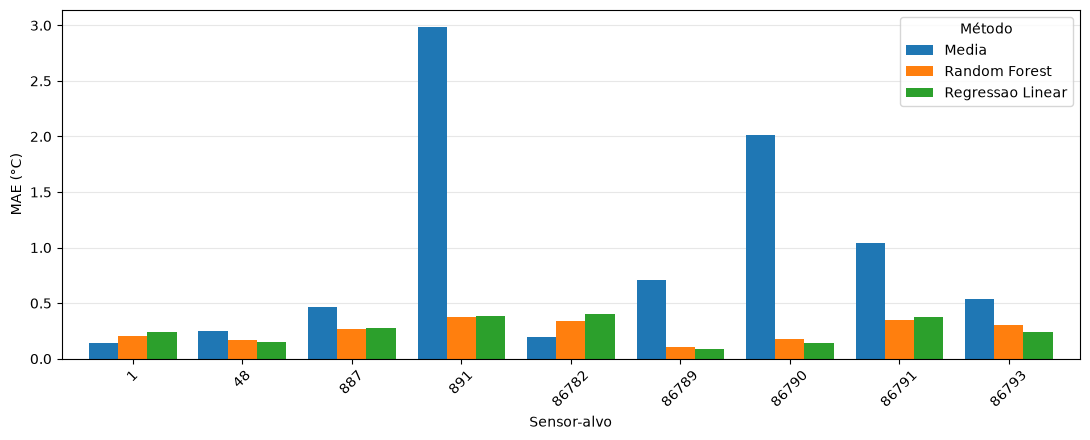

In [29]:
comparacao = resultados_df.pivot(
    index="sensor_alvo",
    columns="metodo",
    values="MAE",
).reindex(SENSOR_IDS)

ax = comparacao.plot(
    kind="bar",
    figsize=(11, 4.5),
    width=0.8,
)

ax.set(
    xlabel="Sensor-alvo",
    ylabel="MAE (°C)",
)

ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(title="Método")

plt.tight_layout()

plt.savefig(
    FIG_DIR / "mae_por_sensor.pdf",
    bbox_inches="tight",
)

plt.savefig(
    FIG_DIR / "mae_por_sensor.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [30]:
for sensor_alvo in SENSOR_IDS:
    fig, eixos = plt.subplots(
        2,
        1,
        figsize=(11, 6),
        sharex=True,
    )

    eixos[0].plot(
        teste.index,
        teste[sensor_alvo],
        label="Real",
        color="black",
        linewidth=1.4,
    )

    for metodo in ["Media", "Regressao Linear", "Random Forest"]:
        serie = (
            previsoes_df[
                (previsoes_df["sensor_alvo"] == sensor_alvo)
                & (previsoes_df["metodo"] == metodo)
            ]
            .sort_values("timestamp")
        )

        eixos[0].plot(
            serie["timestamp"],
            serie["temperatura_estimada"],
            label=metodo,
            linewidth=0.8,
            alpha=0.8,
        )

        eixos[1].plot(
            serie["timestamp"],
            serie["residuo"],
            label=metodo,
            linewidth=0.8,
            alpha=0.8,
        )

    eixos[0].set_ylabel("Temperatura (°C)")
    eixos[0].set_title(f"Reconstrução do sensor {sensor_alvo}")
    eixos[0].legend(ncol=2)

    eixos[1].axhline(
        0,
        color="black",
        linewidth=0.8,
        linestyle="--",
    )

    eixos[1].set(
        xlabel="Data e horário (UTC)",
        ylabel="Estimativa − real (°C)",
    )

    for ax in eixos:
        ax.grid(alpha=0.3)

    fig.autofmt_xdate()
    fig.tight_layout()

    fig.savefig(
        FIG_DIR / f"reconstrucao_sensor_{sensor_alvo}.pdf",
        bbox_inches="tight",
    )

    plt.close(fig)

print("Figuras de reconstrução salvas em:", FIG_DIR)

Figuras de reconstrução salvas em: /home/gustavomoura/Documents/temperatureMonitoring/code/tcc/results/experimentos/figuras


In [31]:
QUANTIDADES = [1, 2, 3, 4, 6, 8]

correlacoes_treino = treino.corr(method="pearson")
resultados_quantidade = []

for sensor_alvo in SENSOR_IDS:
    ranking = (
        correlacoes_treino[sensor_alvo]
        .drop(sensor_alvo)
        .sort_values(
            ascending=False,
            kind="stable",
        )
    )

    if ranking.isna().any():
        raise ValueError(
            f"Correlação indefinida para o alvo {sensor_alvo}."
        )

    for k in QUANTIDADES:
        sensores_entrada = ranking.index[:k].tolist()

        modelo = LinearRegression()

        modelo.fit(
            treino[sensores_entrada],
            treino[sensor_alvo],
        )

        estimativas = modelo.predict(
            teste[sensores_entrada]
        )

        resultados_quantidade.append({
            "sensor_alvo": sensor_alvo,
            "metodo": "Regressao Linear",
            "selecao": "Pearson decrescente no treinamento",
            "k": k,
            "sensores_entrada": json.dumps(
                [int(sensor) for sensor in sensores_entrada]
            ),
            "n_treino": len(treino),
            "n_teste": len(teste),
            **calcular_metricas(
                teste[sensor_alvo],
                estimativas,
            ),
        })

quantidade_df = pd.DataFrame(resultados_quantidade)

resumo_quantidade = (
    quantidade_df
    .groupby("k")
    .agg(
        MAE_medio=("MAE", "mean"),
        MAE_desvio_entre_alvos=("MAE", "std"),
        RMSE_medio=("RMSE", "mean"),
        R2_medio=("R2", "mean"),
    )
    .reset_index()
)

display(resumo_quantidade.round(6))

quantidade_df.to_csv(
    TABLE_DIR / "quantidade_sensores_por_alvo.csv",
    index=False,
)

resumo_quantidade.to_csv(
    TABLE_DIR / "resumo_quantidade_sensores.csv",
    index=False,
)

# Com oito entradas, os resultados devem coincidir
# com a regressão linear da comparação principal.
referencia = (
    resultados_df[
        resultados_df["metodo"] == "Regressao Linear"
    ]
    .set_index("sensor_alvo")
    .sort_index()
)

com_oito = (
    quantidade_df[quantidade_df["k"] == 8]
    .set_index("sensor_alvo")
    .sort_index()
)

np.testing.assert_allclose(
    referencia[["MAE", "RMSE", "R2"]].to_numpy(),
    com_oito[["MAE", "RMSE", "R2"]].to_numpy(),
    rtol=1e-6,
    atol=1e-8,
)

print("Conferência com oito entradas: resultados compatíveis.")

,k,MAE_medio,MAE_desvio_entre_alvos,RMSE_medio,R2_medio
0,1,0.295883,0.100510,0.369577,0.815977
1,2,0.255372,0.100773,0.321969,0.854911
2,3,0.245037,0.087361,0.310595,0.875297
3,4,0.238224,0.090828,0.302466,0.880467
4,6,0.257273,0.102762,0.324517,0.863725
5,8,0.256674,0.113988,0.324864,0.849744


Conferência com oito entradas: resultados compatíveis.


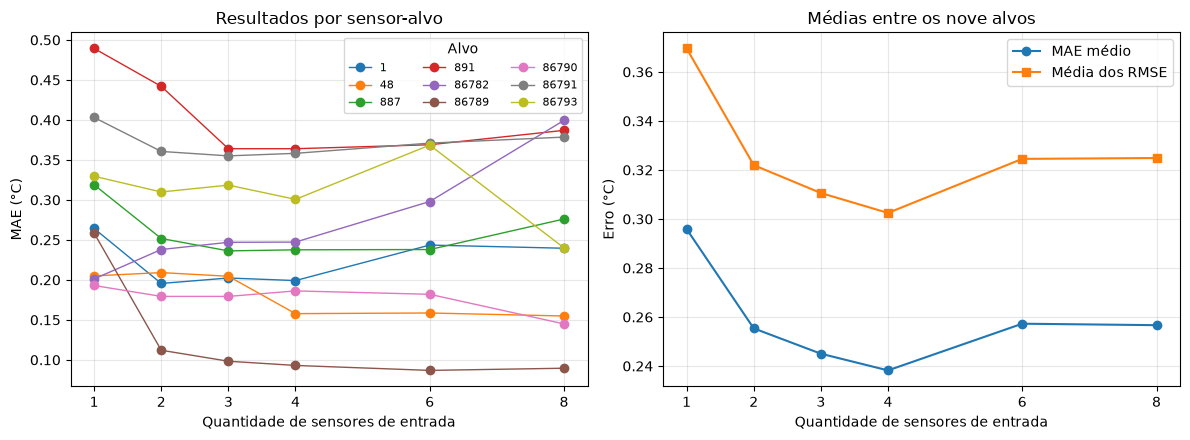

In [32]:
fig, eixos = plt.subplots(
    1,
    2,
    figsize=(12, 4.5),
)

for sensor_alvo, grupo in quantidade_df.groupby("sensor_alvo"):
    eixos[0].plot(
        grupo["k"],
        grupo["MAE"],
        marker="o",
        linewidth=1,
        label=str(sensor_alvo),
    )

eixos[0].set(
    xlabel="Quantidade de sensores de entrada",
    ylabel="MAE (°C)",
    title="Resultados por sensor-alvo",
)

eixos[0].legend(
    title="Alvo",
    fontsize=8,
    ncol=3,
)

eixos[1].plot(
    resumo_quantidade["k"],
    resumo_quantidade["MAE_medio"],
    marker="o",
    label="MAE médio",
)

eixos[1].plot(
    resumo_quantidade["k"],
    resumo_quantidade["RMSE_medio"],
    marker="s",
    label="Média dos RMSE",
)

eixos[1].set(
    xlabel="Quantidade de sensores de entrada",
    ylabel="Erro (°C)",
    title="Médias entre os nove alvos",
)

eixos[1].legend()

for ax in eixos:
    ax.set_xticks(QUANTIDADES)
    ax.grid(alpha=0.3)

fig.tight_layout()

fig.savefig(
    FIG_DIR / "erro_quantidade_sensores.pdf",
    bbox_inches="tight",
)

fig.savefig(
    FIG_DIR / "erro_quantidade_sensores.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [33]:
registro = {
    "executado_em_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "arquivo_dados": str(ARQUIVO_DADOS.relative_to(ROOT)),
    "sha256_dados": hashlib.sha256(
        ARQUIVO_DADOS.read_bytes()
    ).hexdigest(),
    "versoes": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
    },
    "sensor_ids": SENSOR_IDS,
    "fracao_treino": FRACAO_TREINO,
    "embaralhamento": False,
    "n_treino": len(treino),
    "n_teste": len(teste),
    "inicio_treino_utc": treino.index.min().isoformat(),
    "fim_treino_utc": treino.index.max().isoformat(),
    "inicio_teste_utc": teste.index.min().isoformat(),
    "fim_teste_utc": teste.index.max().isoformat(),
    "parametros_regressao_linear": LinearRegression().get_params(),
    "parametros_random_forest": parametros_rf,
    "quantidades_avaliadas": QUANTIDADES,
    "selecao_sensores": (
        "Correlação de Pearson decrescente, "
        "calculada exclusivamente no treinamento"
    ),
    "agregacao_metricas": (
        "Média aritmética das métricas individuais dos nove alvos"
    ),
    "definicao_residuo": "temperatura_estimada - temperatura_real",
}

(RESULTS_DIR / "configuracao_execucao.json").write_text(
    json.dumps(
        registro,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

print("Execução documentada.")
print("Métricas por alvo:", len(resultados_df), "(esperado: 27)")
print("Linhas de previsões:", len(previsoes_df))
print("Avaliações por quantidade:", len(quantidade_df), "(esperado: 54)")

Execução documentada.
Métricas por alvo: 27 (esperado: 27)
Linhas de previsões: 104436
Avaliações por quantidade: 54 (esperado: 54)
